# 5. Học không giám sát – Phân cụm bài báo theo chủ đề

**Mục tiêu:** nhóm bài theo nội dung, giảm các cụm chỉ phản ánh video/văn nói và cung cấp bằng chứng kiểm tra chất lượng cụm.

Sử dụng **TF-IDF hướng chủ đề (unigram + bigram, lọc từ văn phong) → LSA 100 chiều → K-Means**. Khảo sát liên tiếp K=2–16 qua ba seed; chọn thủ công **K=9** sau khi đối chiếu silhouette, CH, DB, độ ổn định và kích thước cụm.

Nhãn `label` và `subject` chỉ dùng sau khi chốt mô hình. Các hàm nằm trong `topic_clustering.py`; bộ lọc ở đây chỉ dành cho phân cụm, không sửa dữ liệu hay mô hình phân loại.


In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_samples
from scipy.stats import chi2_contingency

from topic_clustering import (
    TOPIC_STOP_WORDS, build_features, evaluate_labels, search_clusters,
    keyword_table, article_tables, fitted_pipeline, predict_topics,
)

SEED = 42
SEEDS = (42, 17, 93)
K_VALUES = tuple(range(2, 17))  # Thử liên tiếp K=2 đến K=16.
N_INIT = 10
SAMPLE_SIZE = 3000
DIMENSIONS = 100
RESULTS_DIR = Path("results/clustering")
MODELS_DIR = Path("models")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("data/processed/news_clean.csv", keep_default_na=False)
assert df["raw_id"].is_unique, "raw_id phải duy nhất để đối chiếu bài báo."
print(f"Đọc {len(df):,} bài. Chọn mô hình chỉ từ clean_text.")

Đọc 38,821 bài. Chọn mô hình chỉ từ clean_text.


## 1. Biểu diễn văn bản và mẫu đánh giá

- **TF-IDF hướng chủ đề:** tối đa 30.000 đặc trưng unigram + bigram, `min_df=10`, `max_df=0.4`; lọc stop-word tiếng Anh cùng danh sách cố định từ văn nói/định dạng như `say`, `get`, `video`, `watch`, `via`.
- Bigram như `north korea`, `supreme court` giữ thông tin cụm từ. Bộ lọc là giả định thiết kế; các từ bị bỏ vẫn có thể chứa nội dung nên cần kiểm tra và không khẳng định đã loại hết ảnh hưởng văn phong.
- **Kết quả thực tế:** 38.821 bài đầu vào, 38.820 bài có đặc trưng và một bài được ghi riêng với nhãn `-1`. Ma trận TF-IDF có 30.000 đặc trưng; LSA giảm xuống 100 chiều rồi chuẩn hóa, dùng float64.
- LSA giữ khoảng **12,50% phương sai**. Đây là cấu hình giảm chiều đã sử dụng, chưa có khảo sát độ nhạy theo số chiều; phần thông tin bị bỏ là một giới hạn của biểu diễn.

K-Means học trên **toàn bộ 38.820 bài hợp lệ**. Mẫu ngẫu nhiên cố định **3.000 bài** chỉ dùng tính hai loại silhouette để giới hạn chi phí tính khoảng cách. Mọi K đều dùng cùng mẫu, giúp so sánh nhất quán; 3.000 là lựa chọn thực nghiệm theo tài nguyên, chưa được chứng minh là kích thước tối ưu hay đại diện hoàn toàn.

Seed lấy mẫu là 42 để tái lập đúng các bài đã chọn khi dữ liệu và thứ tự dòng giữ nguyên. Các seed K-Means (42, 17, 93) dùng để kiểm tra độ nhạy theo khởi tạo; số 42 không có ưu thế thống kê đặc biệt.

Cosine silhouette được tính trong TF-IDF trước LSA; silhouette Euclidean được tính trong LSA. **CH và DB dùng toàn bộ vector LSA đã chuẩn hóa**, không chỉ mẫu 3.000 bài. Các chỉ số đo trên các không gian khác nhau nên không so trực tiếp giá trị hay cộng điểm thô với nhau.


In [2]:
with threadpool_limits(limits=4):
    topic_features = build_features(df["clean_text"], topic_focused=True,
                                    seed=SEED, dimensions=DIMENSIONS)

valid = topic_features["valid"]
work = df.loc[valid].reset_index(drop=True)
excluded = df.loc[~valid, ["raw_id", "title"]].copy()
excluded["reason"] = "No TF-IDF features after filtering"
excluded.to_csv(RESULTS_DIR / "excluded_articles.csv", index=False)

X = topic_features["dense"][valid]
X_tfidf = topic_features["sparse"][valid]
sample_indices = np.sort(np.random.default_rng(SEED).choice(
    len(work), size=min(SAMPLE_SIZE, len(work)), replace=False))
reference_sample = X_tfidf[sample_indices]
work.iloc[sample_indices][["raw_id"]].to_csv(RESULTS_DIR / "evaluation_sample.csv", index=False)
(RESULTS_DIR / "topic_stop_words.txt").write_text("\n".join(TOPIC_STOP_WORDS), encoding="utf-8")

print(f"Phân cụm {len(work):,} bài; loại {len(excluded)} bài không có đặc trưng.")
print(f"Mẫu đánh giá: {len(sample_indices):,} bài; LSA: {DIMENSIONS} chiều.")
print("TF-IDF hướng chủ đề:", topic_features["sparse"].shape)
print("Tỷ lệ phương sai LSA giữ lại:",
      round(float(topic_features["svd"].explained_variance_ratio_.sum()), 4))


Phân cụm 38,820 bài; loại 1 bài không có đặc trưng.
Mẫu đánh giá: 3,000 bài; LSA: 100 chiều.
TF-IDF hướng chủ đề: (38821, 30000)
Tỷ lệ phương sai LSA giữ lại: 0.125


## 2. Khảo sát K và chọn thủ công

Mỗi K trong `K_VALUES` chạy với các seed trong `SEEDS`, mỗi seed dùng `N_INIT` lần khởi tạo.

Chạy cell khảo sát để xem bảng tổng hợp, kết quả từng seed và sáu biểu đồ, sau đó tự đặt `K` trong cell chọn bên dưới. Cân nhắc:
- **Cosine silhouette TF-IDF:** cao hơn thể hiện các cụm tách biệt hơn; xem thêm độ lệch chuẩn giữa seed.
- **Calinski–Harabasz (CH):** cao hơn thể hiện tỷ lệ phân tán giữa cụm so với trong cụm tốt hơn.
- **Davies–Bouldin (DB):** thấp hơn thể hiện các cụm gọn và tách biệt hơn theo khoảng cách Euclidean.
- **Stability ARI:** cao hơn thể hiện kết quả ít thay đổi theo seed. Đây là ARI giữa các lần phân cụm, không dùng Fake/True.
- **Min/Max cluster share:** kiểm tra cụm quá nhỏ hoặc một cụm chiếm phần lớn dữ liệu.
- **Inertia:** tham khảo điểm khuỷu tay; inertia thường giảm khi tăng K.

Không áp dụng ngưỡng loại hay quy tắc chọn K tự động. Bạn tự giải thích sự đánh đổi giữa các chỉ số khi thuyết trình. Giữ đúng mô hình của seed đầu tiên đã đánh giá, không fit lại.

CH và DB dùng toàn bộ dữ liệu LSA, được báo trung bình và độ lệch chuẩn qua các seed. Các chỉ số có thể ưu tiên K khác nhau; kết hợp với độ ổn định và bài đại diện để giải thích lựa chọn.


K= 2: cosine=0.0077, CH=1593.94, DB=4.8367, stability=0.998


K= 3: cosine=0.0079, CH=1328.35, DB=4.7376, stability=0.990


K= 4: cosine=0.0080, CH=1193.48, DB=4.3388, stability=1.000


K= 5: cosine=0.0089, CH=1094.01, DB=3.9423, stability=0.834


K= 6: cosine=0.0099, CH=1029.42, DB=3.7539, stability=0.754


K= 7: cosine=0.0118, CH=980.41, DB=3.6539, stability=0.990


... (9 outputs left out)

Bảng tổng hợp theo K:


,Silhouette TF-IDF cosine,Silhouette TF-IDF std,Silhouette LSA Euclidean,Calinski-Harabasz LSA,Calinski-Harabasz std,Davies-Bouldin LSA,Davies-Bouldin std,Stability ARI,Min cluster share,Max cluster share,Inertia
K,,,,,,,,,,,
2,0.00768,0.00000,0.03888,1593.93877,0.00016,4.83675,0.00068,0.99794,0.42308,0.57692,30763.65722
3,0.00795,0.00001,0.03937,1328.34713,0.01782,4.73760,0.00084,0.98997,0.31028,0.35845,29975.31768
4,0.00804,0.00000,0.03744,1193.47582,0.00038,4.33881,0.00012,0.99952,0.14709,0.32146,29322.16383
5,0.00891,0.00031,0.04328,1094.00746,3.77563,3.94233,0.04551,0.83412,0.03202,0.30848,28781.97625
6,0.00994,0.00044,0.04750,1029.42250,13.28501,3.75394,0.06837,0.75419,0.03143,0.27635,28277.12551
7,0.01177,0.00001,0.05568,980.41380,0.00286,3.65387,0.00084,0.99014,0.03202,0.25273,27811.73500
8,0.01198,0.00001,0.05484,936.37449,0.00650,3.59472,0.00147,0.98586,0.03145,0.21607,27399.59278
9,0.01215,0.00001,0.05646,896.88692,0.00163,3.48726,0.00056,0.98999,0.03138,0.21507,27029.79768
10,0.01234,0.00000,0.05788,862.52242,0.00711,3.51421,0.00053,0.98893,0.03145,0.19438,26688.65864


Kết quả chi tiết từng seed:


,K,Seed,Inertia,Silhouette TF-IDF cosine,Silhouette LSA Euclidean,Calinski-Harabasz LSA,Davies-Bouldin LSA,Min cluster share,Max cluster share
0,2,42,30763.65694,0.00768,0.03884,1593.93887,4.83579,0.42308,0.57692
1,2,17,30763.65667,0.00768,0.03890,1593.93890,4.83718,0.42380,0.57620
2,2,93,30763.65806,0.00768,0.03890,1593.93854,4.83728,0.42385,0.57615
3,3,42,29975.35573,0.00794,0.03938,1328.32366,4.73660,0.31028,0.35845
4,3,17,29975.28651,0.00795,0.03932,1328.36683,4.73865,0.31296,0.35574
5,3,93,29975.31082,0.00795,0.03942,1328.35090,4.73755,0.31097,0.35760
6,4,42,29322.16298,0.00804,0.03744,1193.47636,4.33867,0.14709,0.32143
7,4,17,29322.16386,0.00804,0.03744,1193.47558,4.33897,0.14711,0.32138
8,4,93,29322.16466,0.00804,0.03744,1193.47553,4.33879,0.14722,0.32146
9,5,42,28774.85411,0.00914,0.04461,1096.67785,3.91110,0.03205,0.29132


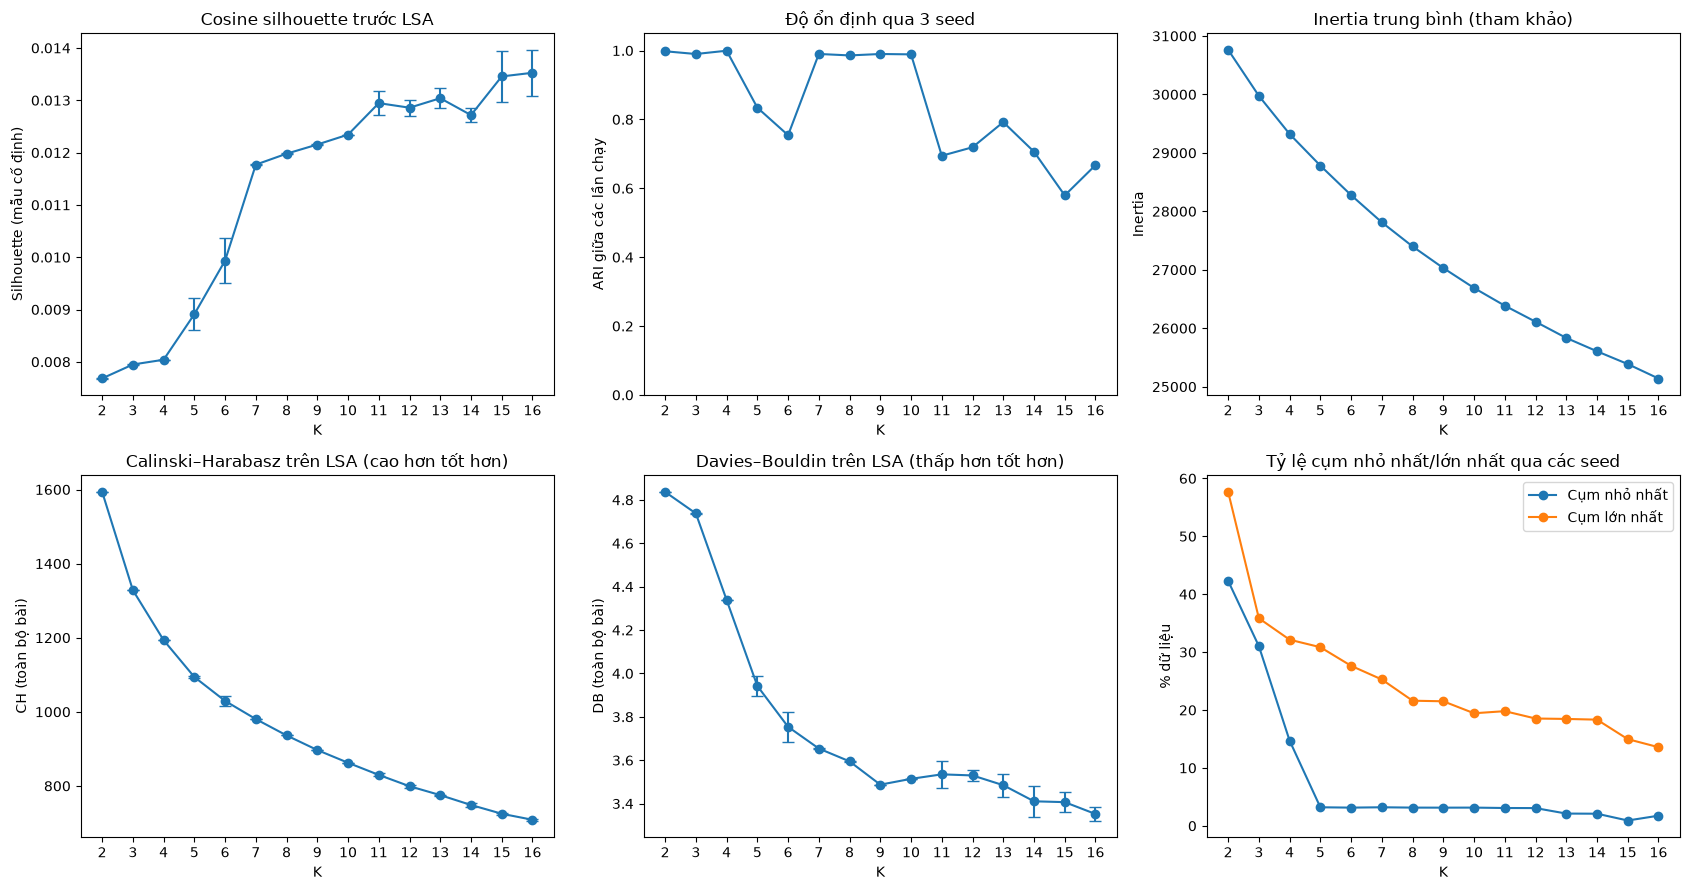

In [3]:
with threadpool_limits(limits=4):
    k_scores, k_runs, candidate_models = search_clusters(
        X, reference_sample, sample_indices, k_values=K_VALUES,
        seeds=SEEDS, n_init=N_INIT)


k_scores.to_csv(RESULTS_DIR / "k_selection.csv")
k_runs.to_csv(RESULTS_DIR / "k_runs.csv", index=False)
print("Bảng tổng hợp theo K:")
with pd.option_context("display.max_columns", None):
    display(k_scores.round(5))
print("Kết quả chi tiết từng seed:")
with pd.option_context("display.max_columns", None):
    display(k_runs.round(5))

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.ravel()
axes[0].errorbar(k_scores.index, k_scores["Silhouette TF-IDF cosine"],
                 yerr=k_scores["Silhouette TF-IDF std"], marker="o", capsize=4)
axes[0].set(title="Cosine silhouette trước LSA", xlabel="K", ylabel="Silhouette (mẫu cố định)")
axes[1].plot(k_scores.index, k_scores["Stability ARI"], marker="o")
axes[1].set(title=f"Độ ổn định qua {len(SEEDS)} seed", xlabel="K", ylabel="ARI giữa các lần chạy", ylim=(0, 1.05))
axes[2].plot(k_scores.index, k_scores["Inertia"], marker="o")
axes[2].set(title="Inertia trung bình (tham khảo)", xlabel="K", ylabel="Inertia")
axes[3].errorbar(k_scores.index, k_scores["Calinski-Harabasz LSA"],
                 yerr=k_scores["Calinski-Harabasz std"], marker="o", capsize=4)
axes[3].set(title="Calinski–Harabasz trên LSA (cao hơn tốt hơn)", xlabel="K", ylabel="CH (toàn bộ bài)")
axes[4].errorbar(k_scores.index, k_scores["Davies-Bouldin LSA"],
                 yerr=k_scores["Davies-Bouldin std"], marker="o", capsize=4)
axes[4].set(title="Davies–Bouldin trên LSA (thấp hơn tốt hơn)", xlabel="K", ylabel="DB (toàn bộ bài)")
axes[5].plot(k_scores.index, k_scores["Min cluster share"] * 100, marker="o", label="Cụm nhỏ nhất")
axes[5].plot(k_scores.index, k_scores["Max cluster share"] * 100, marker="o", label="Cụm lớn nhất")
axes[5].set(title="Tỷ lệ cụm nhỏ nhất/lớn nhất qua các seed", xlabel="K", ylabel="% dữ liệu")
axes[5].legend()
for ax in axes:
    ax.set_xticks(k_scores.index)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "k_selection.png", dpi=150, bbox_inches="tight")
plt.show()

### Chọn thủ công K=9 và giải thích lựa chọn

**Cơ sở:** 15 giá trị K từ 2 đến 16 đã chạy trên cùng 38.820 bài, ba seed (42, 17, 93), `n_init=10`; hai silhouette dùng cùng mẫu ngẫu nhiên 3.000 bài, CH và DB dùng toàn bộ LSA đã chuẩn hóa. Các số dưới đây là trung bình qua ba seed; ARI đo độ ổn định giữa các lần chạy, không so với Fake/True.

| K | Cosine silhouette ↑ | CH ↑ | DB ↓ | ARI ổn định ↑ |
|---|---:|---:|---:|---:|
| 7 | 0,011770 | 980,41 | 3,65387 | 0,99014 |
| 8 | 0,011979 | 936,37 | 3,59472 | 0,98586 |
| **9** | **0,012154** | **896,89** | **3,48726** | **0,98999** |
| 10 | 0,012343 | 862,52 | 3,51421 | 0,98893 |
| 13 | 0,013039 | 775,20 | 3,48490 | 0,79221 |
| 16 | 0,013526 | 708,67 | 3,35219 | 0,66730 |

**Vì sao chọn K=9?**

1. **So với K=7–8:** silhouette cao hơn và DB thấp hơn. ARI vẫn gần 0,99; so với K=8, ARI còn cao hơn. Đổi lại, CH giảm, nên không nói K=9 tốt hơn trên mọi tiêu chí.
2. **So với K=10:** CH cao hơn (896,89 so với 862,52), DB thấp hơn (3,48726 so với 3,51421), ARI hơi cao hơn (0,98999 so với 0,98893) và ít hơn một cụm. Đổi lại, cosine silhouette thấp hơn khoảng **0,000189** (khoảng **1,53%** so với K=10), silhouette Euclidean LSA cũng thấp hơn (0,056464 so với 0,057884), inertia cao hơn. Chấp nhận sự đánh đổi này để giữ ít cụm hơn với độ ổn định cao và hai chỉ số CH/DB thuận lợi hơn; chưa có kiểm định để khẳng định các chênh lệch nhỏ có ý nghĩa thống kê.
3. **So với K=11–16:** ARI của các K này chỉ khoảng **0,579–0,792**, thấp hơn rõ rệt mức 0,990 của K=9. Riêng K=13 có DB gần K=9 (3,48490), nhưng dao động DB giữa seed lớn hơn (std 0,05390 so với 0,00056). K lớn hơn có thể có silhouette và DB tốt hơn, nhưng kết quả nhạy với khởi tạo hơn.
4. **Kích thước cụm:** qua ba seed, cụm nhỏ nhất chiếm **3,14%**, cụm lớn nhất **21,51%** dữ liệu. Không có cụm cực nhỏ trong lần khảo sát này; các tỷ lệ chỉ hỗ trợ kiểm tra phân bố, không tự chứng minh ý nghĩa chủ đề.

**Vì sao không chọn K=2 hoặc K=4?** K=2 có CH cao nhất (1593,94), K=4 có ARI cao nhất (0,99952), nhưng cosine silhouette tương ứng chỉ 0,007683 và 0,008040, DB là 4,83675 và 4,33881, kém hơn K=9 theo hai chỉ số đó. Nhóm chọn mức phân chia chi tiết hơn để khám phá chủ đề, thay vì tối đa một chỉ số riêng lẻ.

**Cách trả lời ngắn khi bảo vệ:**

> “Em khảo sát K từ 2 đến 16 trên cùng dữ liệu và cùng mẫu đánh giá. Em chọn K=9 vì độ ổn định giữa ba seed gần 0,99. So với K=8, silhouette tốt hơn và DB thấp hơn; so với K=10, CH cao hơn, DB thấp hơn, độ ổn định hơi cao hơn và ít hơn một cụm, trong khi cosine silhouette chỉ thấp hơn khoảng 0,000189. Các K từ 11 trở lên có thể cải thiện một số chỉ số nhưng độ ổn định giảm rõ rệt. Vì vậy, K=9 là lựa chọn đánh đổi phù hợp trong phạm vi khảo sát, không phải số chủ đề đúng duy nhất hay tối ưu theo mọi chỉ số.”

K được chọn thủ công sau khi xem số liệu, không có bộ lọc ngưỡng hay phép bỏ phiếu tự động giữa các chỉ số. CH/DB cùng phản ánh hình học LSA, nên không xem chúng là các bằng chứng độc lập hoàn toàn. Sau khi chốt K mới xem nhãn Fake/True và `subject`; chúng không được dùng để chọn K.

Nếu đổi K, sửa cả phần giải thích rồi chạy lại cell chọn và toàn bộ các cell phía sau.


In [4]:
K = 9  # Chọn thủ công theo sự đánh đổi giữa các chỉ số đã khảo sát.
if K not in candidate_models:
    raise ValueError(f"K={K} chưa được khảo sát. Chọn trong {list(candidate_models)} hoặc sửa K_VALUES rồi chạy lại.")

kmeans = candidate_models[K]
work["cluster"] = kmeans.labels_
k_scores["Selected"] = k_scores.index == K
k_scores.to_csv(RESULTS_DIR / "k_selection.csv")
print(f"Chọn thủ công K={K}; dùng candidate seed={SEEDS[0]}, n_init={N_INIT}.")
display(k_scores.round(5))


Chọn thủ công K=9; dùng candidate seed=42, n_init=10.


,Silhouette TF-IDF cosine,Silhouette TF-IDF std,Silhouette LSA Euclidean,Calinski-Harabasz LSA,Calinski-Harabasz std,Davies-Bouldin LSA,Davies-Bouldin std,Stability ARI,Min cluster share,Max cluster share,Inertia,Selected
K,,,,,,,,,,,,
2,0.00768,0.00000,0.03888,1593.93877,0.00016,4.83675,0.00068,0.99794,0.42308,0.57692,30763.65722,False
3,0.00795,0.00001,0.03937,1328.34713,0.01782,4.73760,0.00084,0.98997,0.31028,0.35845,29975.31768,False
4,0.00804,0.00000,0.03744,1193.47582,0.00038,4.33881,0.00012,0.99952,0.14709,0.32146,29322.16383,False
5,0.00891,0.00031,0.04328,1094.00746,3.77563,3.94233,0.04551,0.83412,0.03202,0.30848,28781.97625,False
6,0.00994,0.00044,0.04750,1029.42250,13.28501,3.75394,0.06837,0.75419,0.03143,0.27635,28277.12551,False
7,0.01177,0.00001,0.05568,980.41380,0.00286,3.65387,0.00084,0.99014,0.03202,0.25273,27811.73500,False
8,0.01198,0.00001,0.05484,936.37449,0.00650,3.59472,0.00147,0.98586,0.03145,0.21607,27399.59278,False
9,0.01215,0.00001,0.05646,896.88692,0.00163,3.48726,0.00056,0.98999,0.03138,0.21507,27029.79768,True
10,0.01234,0.00000,0.05788,862.52242,0.00711,3.51421,0.00053,0.98893,0.03145,0.19438,26688.65864,False


## 3. Đánh giá mô hình K=9 đã chọn

Giữ đúng mô hình **seed 42, `n_init=10`** đã đánh giá khi khảo sát K=9. Không đổi seed hoặc khởi tạo lại để tìm kết quả thuận lợi hơn.

| Chỉ số | Trung bình qua ba seed tại K=9 | Mô hình cuối seed 42 |
|---|---:|---:|
| Cosine silhouette TF-IDF | 0,012154 | 0,012136 |
| Silhouette Euclidean LSA | 0,056464 | 0,056370 |
| CH trên toàn bộ LSA | 896,89 | 896,89 |
| DB trên toàn bộ LSA | 3,48726 | 3,48653 |
| Inertia | 27.029,80 | 27.029,79 |

**ARI ổn định = 0,989994** là trung bình ARI của các cặp phân cụm giữa ba seed, không phải chỉ số riêng của seed 42 và không phải “độ chính xác 99%”.

`k_selection.csv` ghi trung bình/độ lệch theo K, `k_runs.csv` ghi từng seed; `final_metrics.csv` ghi điểm của mô hình seed 42 thực tế cùng ARI tổng hợp. Vì vậy, cosine silhouette trung bình **0,012154** và điểm seed 42 **0,012136** khác nhau là đúng, không phải lỗi tính toán.

Silhouette thấp cho thấy các chủ đề còn chồng lấn. CH/DB và độ ổn định hỗ trợ giải thích lựa chọn K; chúng không tự xác nhận các cụm mang chủ đề đúng.


In [5]:
with threadpool_limits(limits=4):
    selected_metrics = evaluate_labels(X, reference_sample, kmeans.labels_, sample_indices)
final_metrics = pd.DataFrame([{
    "Model": f"K-Means, K={K}",
    "K": K,
    **selected_metrics,
    "Stability ARI": k_scores.loc[K, "Stability ARI"],
    "Inertia": kmeans.inertia_,
}]).set_index("Model")
final_metrics.to_csv(RESULTS_DIR / "final_metrics.csv")
display(final_metrics.round(5))


,K,Silhouette TF-IDF cosine,Silhouette LSA Euclidean,Calinski-Harabasz LSA,Davies-Bouldin LSA,Min cluster share,Max cluster share,Stability ARI,Inertia
Model,,,,,,,,,
"K-Means, K=9",9,0.01214,0.05637,896.88922,3.48653,0.0314,0.21458,0.98999,27029.78651


## 4. Từ khóa có trọng số và bài đại diện

Xếp từ khóa theo **TF-IDF trung bình × log(1 + lift)**; lift là tỷ lệ TF-IDF trung bình trong cụm so với toàn bộ dữ liệu. Chỉ giữ từ xuất hiện trong ≥ 1% bài của cụm để giảm từ quá hiếm. CSV lưu cả trọng số và tỷ lệ bài chứa từ.

Mỗi cụm có ba bài gần tâm nhất để kiểm tra nội dung. Tên chủ đề dưới đây được diễn giải từ từ khóa, tiêu đề và nội dung trích đoạn của bài đại diện ở **mô hình K=9, seed 42**; không phải nhãn chuẩn hay kết quả phân loại đã được xác nhận.

| Cụm | Số bài | % dữ liệu | Tên chủ đề gợi ý | Nhận xét |
|---|---:|---:|---|---|
| 0 | 8.330 | 21,46 | Bình luận chính trị–xã hội Mỹ | Rộng; còn dấu hiệu văn phong và nội dung chồng lấn |
| 1 | 5.712 | 14,71 | Chính sách Mỹ: thuế, ngân sách, y tế | Nhiều chính sách trong một cụm; không chỉ riêng thuế |
| 2 | 2.803 | 7,22 | Chính trị châu Âu–EU–Brexit | Bài đại diện gồm Macedonia, Anh và Italy |
| 3 | 4.667 | 12,02 | Bầu cử Mỹ–Clinton và các ứng viên | Gồm cả tin ứng viên và bình luận; không chỉ email Clinton |
| 4 | 1.219 | 3,14 | Bán đảo Triều Tiên–hạt nhân–ngoại giao | Chủ đề rõ hơn theo từ khóa và ba bài đại diện |
| 5 | 7.287 | 18,77 | Tin quốc tế–Trung Đông, Iran/Syria, quân sự | Cụm lớn, phạm vi rộng; cần đọc thêm bài ở ranh giới |
| 6 | 2.849 | 7,34 | Cảnh sát–súng đạn–tội phạm tại Mỹ | Có cả tin tội phạm và bình luận xã hội |
| 7 | 2.820 | 7,26 | Tòa án–Tối cao Pháp viện–pháp luật Mỹ | Ba bài đại diện liên quan các vụ việc ở tòa án |
| 8 | 3.133 | 8,07 | Nga–FBI–điều tra can thiệp bầu cử Mỹ | Nhóm sự kiện/điều tra; chưa chứng minh mọi bài cùng chủ đề |

Cụm lớn nhất là cụm 0 với **8.330 bài (21,46%)**, nhỏ nhất là cụm 4 với **1.219 bài (3,14%)**. Đây là phân bố của mô hình cuối; bảng khảo sát lấy giá trị nhỏ nhất/lớn nhất qua ba seed nên có thể chênh nhẹ.

Các mã 0–8 chỉ định danh các cụm của lần chạy này. Không dùng tên hoặc mã cụm của mô hình K=10 cũ để diễn giải K=9. Cột “Chủ đề gợi ý” trong CSV vẫn giữ ba từ khóa tự động, giúp đối chiếu với tên diễn giải ở trên.


In [6]:
terms = topic_features["tfidf"].get_feature_names_out()
keywords = keyword_table(X_tfidf, terms, work["cluster"].to_numpy())
articles, representatives, boundary = article_tables(work, X, kmeans)
summary = work.groupby("cluster").size().to_frame("Số bài")
summary["% dữ liệu"] = summary["Số bài"] / len(work) * 100
summary["Chủ đề gợi ý"] = keywords[keywords["rank"] <= 3].groupby("cluster")["term"].agg(" / ".join)
summary["Từ khóa"] = keywords[keywords["rank"] <= 10].groupby("cluster")["term"].agg(", ".join)
summary["Bài gần tâm nhất"] = representatives[representatives["rank"] == 1].set_index("cluster")["title"]
keywords.to_csv(RESULTS_DIR / "cluster_keywords.csv", index=False)
representatives.to_csv(RESULTS_DIR / "representative_articles.csv", index=False)
boundary.to_csv(RESULTS_DIR / "boundary_articles.csv", index=False)

assignments = df[["raw_id", "title"]].merge(
    articles.drop(columns="title"), on="raw_id", how="left", validate="one_to_one")
assignments["cluster"] = assignments["cluster"].fillna(-1).astype(int)
assignments.to_csv(RESULTS_DIR / "cluster_articles.csv", index=False)
summary.to_csv(RESULTS_DIR / "cluster_summary.csv")
with pd.option_context("display.max_colwidth", 110):
    display(summary.round(2))
    display(representatives[["cluster", "rank", "raw_id", "title", "distance_to_center"]])

,Số bài,% dữ liệu,Chủ đề gợi ý,Từ khóa,Bài gần tâm nhất
cluster,,,,,
0,8330,21.46,america / woman / racist,"america, woman, racist, tweet, american, right, white, obama, black, fact",Trump: The First President to Turn Postmodernism Against Itself
1,5712,14.71,tax / senate / house,"tax, senate, house, republican, obamacare, legislation, healthcare, congress, budget, representative",Out in the cold: New U.S. budget priorities threaten housing aid programs
2,2803,7.22,eu / european / brexit,"eu, european, brexit, minister, britain, parliament, prime minister, european union, prime, merkel",Macedonia's pro-Western Social Democrats claim victory in local elections
3,4667,12.02,clinton / hillary / hillary clinton,"clinton, hillary, hillary clinton, candidate, presidential, campaign, sander, republican, voter, democratic",Dallas Morning News Endorses Hillary Clinton – The First Democrat In 75 Years
4,1219,3.14,korea / north korea / north,"korea, north korea, north, korean, missile, nuclear, pyongyang, north korean, south korea, china","U.S. challenged by rising North Korea tensions, Russia urges calm"
5,7287,18.77,iran / syria / military,"iran, syria, military, al, islamic, islamic state, saudi, syrian, united, turkey",Sunnistan: US and Allied ‘Safe Zone’ Plan to Take Territorial Booty in Northern Syria
6,2849,7.34,police / officer / police officer,"police, officer, police officer, arrest, shoot, gun, cop, kill, man, black",BREAKING: TEXAS COP STABBED 14 TIMES By Man Who “had a desire to kill a police officer”
7,2820,7.26,court / supreme court / supreme,"court, supreme court, supreme, judge, justice, case, appeal, ruling, attorney, federal",Trump administration in spotlight as U.S. top court returns
8,3133,8.07,russia / russian / intelligence,"russia, russian, intelligence, fbi, comey, investigation, putin, flynn, fbi director, mueller","FBI head confirms Russia election probe, says Moscow backed Trump"


,cluster,rank,raw_id,title,distance_to_center
17432,0,1,22250,Trump: The First President to Turn Postmodernism Against Itself,0.575326
4801,0,2,4801,Legendary Humorist And Radio Host HAMMERS Trump In Devastating Open Letter,0.588088
10057,0,3,10061,“DIRTY JOBS” HOST MIKE ROWE Absolutely Destroys Guy Who Called Him A White Nationalist,0.607096
22966,1,1,28601,Out in the cold: New U.S. budget priorities threaten housing aid programs,0.643955
18345,1,2,23944,Republicans in House seek protection for municipal bonds in tax bill,0.647361
24670,1,3,30308,"Under Trump, Congress likely to pull plug on medical device tax",0.648245
34962,2,1,40885,Macedonia's pro-Western Social Democrats claim victory in local elections,0.603674
13628,2,2,13641,BREAKING: UK PRIME MINISTER David Cameron To Step Down…UKIP Leader Nigel Barage Celebrates Political Earth...,0.606508
30524,2,3,36301,"Italy's 5-Star sheds anti-EU image, calls for reform",0.607445
4737,3,1,4737,Dallas Morning News Endorses Hillary Clinton – The First Democrat In 75 Years,0.524320


## 5. Bài ở ranh giới và hình chiếu minh họa

- `boundary_margin` là khoảng cách tới tâm gần thứ hai trừ khoảng cách tới tâm được gán. Margin nhỏ nghĩa là gần ranh giới; **không phải xác suất hay độ tin cậy đã hiệu chuẩn**.
- PCA 2D chỉ minh họa trên mẫu đánh giá. K-Means chạy trên LSA 100 chiều; không dùng độ tách trong hình 2D làm bằng chứng duy nhất về chất lượng.
- Trên đúng mẫu 3.000 bài, mô hình seed 42 có **759 bài (25,30%) có cosine silhouette âm**. Điều này nghĩa là khoảng cách trung bình của các bài đó tới ít nhất một cụm khác nhỏ hơn khoảng cách trung bình trong cụm được gán, xét trong TF-IDF cosine.
- **Cụm 0:** silhouette trung bình khoảng **−0,00097**, 57,44% bài trong mẫu của cụm có điểm âm. **Cụm 5:** trung bình khoảng **0,00040**, 51,23% có điểm âm. Đây là hai cụm rộng, cần kiểm tra thêm và không nên tuyên bố tất cả cụm đã tách biệt rõ.
- **Cụm 4 (Triều Tiên):** silhouette trung bình mẫu khoảng **0,09940**, không có điểm âm trong 106 bài được lấy vào mẫu của cụm. Kết quả này chỉ mô tả mẫu và khoảng cách, không có nghĩa phân cụm chính xác 100%.

Median margin trên toàn bộ bài hợp lệ khoảng **0,07883**; một số bài có margin rất nhỏ (nhỏ nhất khoảng **0,000012**). CSV bài ranh giới là bằng chứng để kiểm tra các trường hợp đa chủ đề hoặc khó gán, thay vì diễn giải chúng như lỗi đã có nhãn xác nhận.


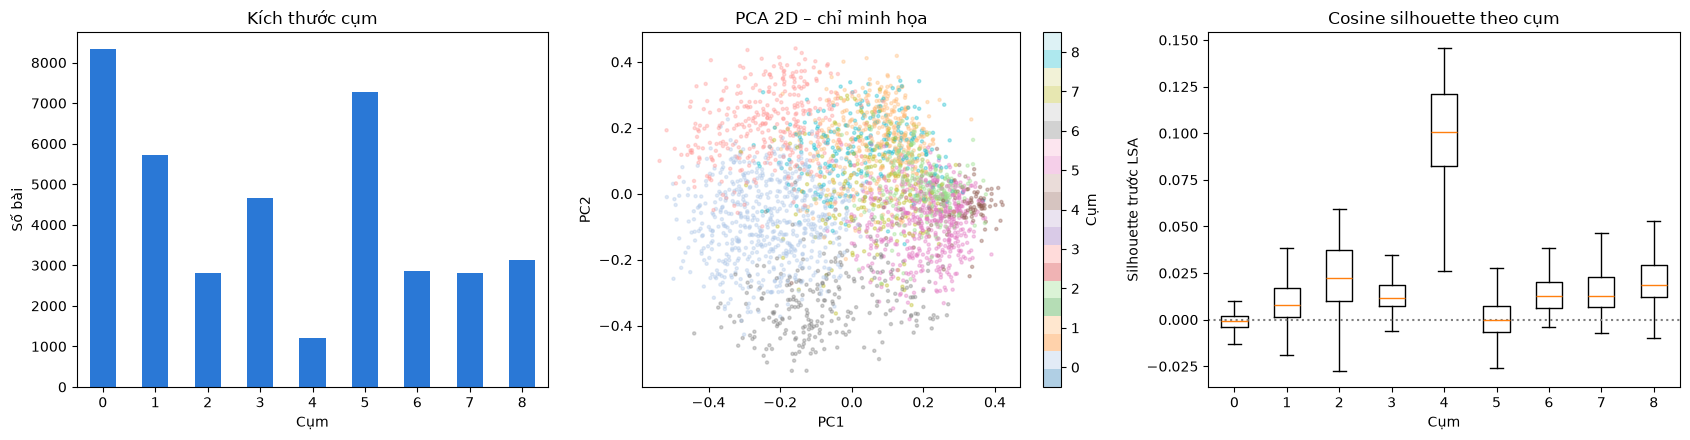

Các bài có margin thấp, cần đọc để kiểm tra ranh giới:


,cluster,raw_id,title,boundary_margin
931,0,931,Trump Brags About Gas Prices And Gets HUMILIATED With Facts,0.000033
6488,0,6488,WATCH: Rep. Ellison Predicts Rise Of Trump Almost A Year Ago,0.000070
20185,1,25795,"In blustery call, Trump pressured Mexico on border wall payment",0.000020
2994,1,2994,GOP Congressman Hosts Repeal Obamacare Town Hall; It Didn’t Go The Way He Wanted (VIDEO),0.000050
33546,2,39429,South Africa's unruly ANC branches kick off race to succeed Zuma,0.000167
36154,2,42141,"Fear driving Cambodian opposition MPs abroad, party says",0.000182
25939,3,31584,"Clinton, Trump to both meet with Egyptian president at U.N.",0.000206
8101,3,8101,Black GOP Candidate: Party Bosses Told Me ‘You Sound Too Black’,0.000306
22949,4,28584,Highlights: The Trump presidency on March 6 at 7:50 p.m. EST,0.000374
24674,4,30312,Trump says U.S.-China relationship must improve,0.001433


In [7]:
with threadpool_limits(limits=4):
    projection = PCA(n_components=2, random_state=SEED).fit_transform(X[sample_indices])
    sample_silhouette = silhouette_samples(reference_sample, kmeans.labels_[sample_indices], metric="cosine")
sample_labels = kmeans.labels_[sample_indices]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
summary["Số bài"].plot.bar(ax=axes[0], color="#2a78d6", rot=0)
axes[0].set(title="Kích thước cụm", xlabel="Cụm", ylabel="Số bài")
scatter = axes[1].scatter(projection[:, 0], projection[:, 1], c=sample_labels,
                          cmap="tab20", s=5, alpha=.35, vmin=-.5, vmax=K-.5)
axes[1].set(title="PCA 2D – chỉ minh họa", xlabel="PC1", ylabel="PC2")
fig.colorbar(scatter, ax=axes[1], ticks=range(K), label="Cụm")
axes[2].boxplot([sample_silhouette[sample_labels == c] for c in range(K)],
                tick_labels=list(range(K)), showfliers=False)
axes[2].axhline(0, color="grey", ls=":")
axes[2].set(title="Cosine silhouette theo cụm", xlabel="Cụm", ylabel="Silhouette trước LSA")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "cluster_overview.png", dpi=150, bbox_inches="tight")
plt.show()
print("Các bài có margin thấp, cần đọc để kiểm tra ranh giới:")
with pd.option_context("display.max_colwidth", 110):
    display(boundary[["cluster", "raw_id", "title", "boundary_margin"]])

## 6. Đối chiếu với nhãn sau khi chốt mô hình

Đến đây mới dùng Fake/True và chuyên mục gốc. Các số của **K=9, seed 42**:

| Chỉ số đối chiếu | Giá trị |
|---|---:|
| ARI giữa cụm và nhãn Fake/True | 0,136176 |
| Cramér's V | 0,646213 |
| Purity | 0,793637 |
| Mốc tỷ lệ lớp đông nhất | 0,539284 |

Các cụm có liên hệ với Fake/True: ví dụ cụm 0 có khoảng **94,83% Fake**, cụm 2 có khoảng **96,18% True**. Từ khóa và chủ đề có thể gắn với văn phong, nguồn và chuyên mục; không thể kết luận mô hình đã độc lập với các yếu tố đó chỉ vì không đưa nhãn vào huấn luyện.

**Không dùng các chỉ số này để chọn K.** ARI ở đây so cụm với nhãn Fake/True, khác với ARI ổn định giữa các seed. Purity khoảng 0,794 không phải độ chính xác chủ đề 79,4%; số cụm và số lớp khác nhau, và purity có thể tăng khi chia thêm cụm. Chuyên mục gốc gắn với nguồn đăng nên cũng không được xem là nhãn chủ đề chuẩn.


In [8]:
ct = pd.crosstab(work["cluster"], work["label"])
chi2, p_value, _, _ = chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
purity = ct.max(axis=1).sum() / ct.to_numpy().sum()
association = pd.Series({
    "ARI (cụm vs nhãn)": adjusted_rand_score(work["label"], work["cluster"]),
    "Cramér's V": cramers_v,
    "p-value χ²": p_value,
    "Độ thuần (purity)": purity,
    "Mốc: tỷ lệ lớp đông nhất": work["label"].value_counts(normalize=True).max(),
})
association.to_frame("Giá trị").to_csv(RESULTS_DIR / "cluster_label_association.csv")
summary["% Fake"] = work.groupby("cluster")["label"].apply(lambda s: (s == 0).mean() * 100)
summary.to_csv(RESULTS_DIR / "cluster_summary.csv")
subject_table = pd.crosstab(work["cluster"], work["subject"])
subject_table.to_csv(RESULTS_DIR / "cluster_subjects.csv")
display(association.to_frame("Giá trị").round(5))
display(subject_table)
display(summary[["Chủ đề gợi ý", "Số bài", "% Fake"]].round(2))

,Giá trị
ARI (cụm vs nhãn),0.13618
Cramér's V,0.64621
p-value χ²,0.00000
Độ thuần (purity),0.79364
Mốc: tỷ lệ lớp đông nhất,0.53928


subject,Government News,News,US_News,left-news,politics,politicsNews,worldnews
cluster,,,,,,,
0,102,4611,176,338,2672,341,90
1,125,724,32,18,472,4108,233
2,12,23,4,5,63,262,2434
3,15,1506,84,17,1483,1550,12
4,3,52,11,1,46,371,735
5,95,148,270,34,439,1631,4670
6,63,700,72,249,772,175,818
7,83,506,33,34,337,1326,501
8,33,780,101,5,536,1448,230


,Chủ đề gợi ý,Số bài,% Fake
cluster,,,
0,america / woman / racist,8330,94.83
1,tax / senate / house,5712,24.00
2,eu / european / brexit,2803,3.82
3,clinton / hillary / hillary clinton,4667,66.53
4,korea / north korea / north,1219,9.27
5,iran / syria / military,7287,13.53
6,police / officer / police officer,2849,65.15
7,court / supreme court / supreme,2820,35.21
8,russia / russian / intelligence,3133,46.44


## 7. Lưu mô hình và kiểm chứng tái sử dụng

`models/topic_clustering.joblib` lưu TF-IDF, LSA, Normalizer và **K-Means K=9, seed 42** đã fit. Đầu vào là `clean_text` từ notebook 3; bài thô cần qua `preprocess_article(title, text)` trước.

Mô hình và các bảng đã được cập nhật đồng bộ theo K=9. Kiểm chứng thực tế: nạp lại mô hình cho nhãn khớp ở 30 bài đã kiểm tra; hai đầu vào rỗng/không có đặc trưng nhận `-1`; bảng gán cụm giữ đủ **38.821 bài**, gồm **38.820 bài ở các cụm 0–8** và **một bài ở -1**; tổng số bài trong bảng chín cụm khớp dữ liệu hợp lệ.

Các phép kiểm tra trên xác nhận tính nhất quán của luồng xử lý và lưu/nạp, không phải kiểm định chất lượng chủ đề hay khả năng khái quát hóa. K-Means vẫn gán mọi bài có đặc trưng vào một cụm dù bài có thể chứa nhiều chủ đề.


In [9]:
pipeline = fitted_pipeline(topic_features, kmeans)
model_path = MODELS_DIR / "topic_clustering.joblib"
joblib.dump(pipeline, model_path)
loaded = joblib.load(model_path)
check_indices = np.linspace(0, len(work) - 1, 30, dtype=int)
with threadpool_limits(limits=4):
    predictions = predict_topics(loaded, work.iloc[check_indices]["clean_text"])
np.testing.assert_array_equal(predictions, kmeans.labels_[check_indices])
assert predict_topics(loaded, ["", "zzzzunknownword"] ).tolist() == [-1, -1]
assert len(assignments) == len(df)
assert int((assignments["cluster"] >= 0).sum()) == len(work)
assert summary["Số bài"].sum() == len(work)
metadata = {
    "tfidf_dtype": "float64", "selected_k": K, "seed": SEED, "seeds": list(SEEDS), "n_init": N_INIT,
    "k_values": list(K_VALUES), "lsa_dimensions": DIMENSIONS,
    "sample_size": len(sample_indices), "clustered_articles": len(work),
    "excluded_articles": len(excluded), "input": "notebook-3 clean_text",
    "selection": "manual choice after inspecting silhouettes, CH, DB, stability, cluster sizes and inertia",
    "selection_reason": "K=9 balances high seed stability with lower DB than K=7/8/10; compared with K=10 it has higher CH, slightly higher ARI and fewer clusters, accepting lower silhouettes and higher inertia. Exploratory choice within K=2..16, not a unique optimum.",
    "metric_scope": {"silhouette": "fixed article sample", "CH_DB": "all normalized LSA vectors"},
    "labels_used_for_selection": False,
}
(RESULTS_DIR / "run_config.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã lưu:", model_path)
print("Kiểm chứng: mô hình nạp lại khớp 30 bài, đầu vào không có đặc trưng nhận -1, tổng số bài khớp.")

Đã lưu: models\topic_clustering.joblib
Kiểm chứng: mô hình nạp lại khớp 30 bài, đầu vào không có đặc trưng nhận -1, tổng số bài khớp.


## Nhận xét tổng hợp và trả lời khi bảo vệ

**Kết luận thực nghiệm:** chọn thủ công **K=9** trong dải K=2–16 trên 38.820 bài. K=9 duy trì ARI ổn định **0,989994**, cosine silhouette trung bình **0,012154**, CH **896,89**, DB **3,48726**. Độ lệch chuẩn qua ba seed của silhouette là khoảng **0,00001379**, CH **0,00163**, DB **0,00056**. Độ ổn định cao chỉ được xác nhận với ba seed đã thử, không bảo đảm trên mọi khởi tạo hoặc dữ liệu mới.

**Lý do chọn:** so với K=8, K=9 có silhouette cao hơn, DB thấp hơn và ARI cao hơn, dù CH giảm. So với K=10, K=9 có CH cao hơn khoảng **3,98%**, DB thấp hơn **0,77%**, ARI nhỉnh hơn và ít hơn một cụm. Chấp nhận cosine silhouette thấp hơn **0,000189** (khoảng **1,53%** so với K=10), silhouette Euclidean thấp hơn và inertia cao hơn để có mức phân chia gọn hơn. Đây là quyết định khám phá sau khi xem số liệu; không có kiểm định cho phép khẳng định K=9 vượt trội có ý nghĩa thống kê.

**Các phản biện cần trả lời thẳng:**

- **“Sao không chọn K=2 vì CH cao nhất?”** CH ưu tiên K=2 trong lần khảo sát này, nhưng silhouette của K=2 chỉ 0,007683 và DB 4,83675, kém hơn K=9 theo hai chỉ số đó. Mục tiêu còn là khám phá nhiều nhóm nội dung; không tối đa CH riêng lẻ.
- **“Sao không chọn K=4 vì ổn định nhất?”** ARI K=4 là 0,99952, nhưng silhouette chỉ 0,008040 và DB 4,33881. Ổn định không đồng nghĩa các chủ đề đã được tách tốt hoặc đủ chi tiết.
- **“Sao không giữ K=10?”** K=10 có hai silhouette tốt hơn và inertia thấp hơn, nhưng K=9 có CH, DB và ARI thuận lợi hơn, đồng thời ít hơn một cụm. Hai phương án đều có cơ sở; nhóm chọn K=9 theo sự đánh đổi nêu trên, không tuyên bố K=10 sai.
- **“Sao không chọn K=13 hoặc K=16?”** K=13 có silhouette 0,013039, DB 3,48490 nhưng ARI chỉ 0,79221. K=16 có silhouette cao nhất (0,013526), DB thấp nhất (3,35219) nhưng ARI chỉ 0,66730. Các kết quả này nhạy với khởi tạo hơn K=9.
- **“Sao không chạy K lớn hơn 16?”** 16 là giới hạn khảo sát ban đầu theo tài nguyên, không phải giới hạn của K-Means. Vì K=16 có silhouette/DB tốt nhất ở biên, chưa loại trừ K lớn hơn có kết quả phù hợp hơn; mở rộng dải và kiểm tra thêm seed/mẫu là bước tiếp theo nếu có thời gian.
- **“Silhouette thấp như vậy có tốt không?”** Điểm thấp và 25,30% bài mẫu có điểm âm cho thấy còn chồng lấn, đặc biệt cụm 0 và 5. K=9 là lựa chọn cân bằng trong các cấu hình đã thử, chưa giải quyết hoàn toàn việc trộn chủ đề. Những nhóm như Triều Tiên, tòa án, EU/Brexit có từ khóa và bài đại diện dễ diễn giải hơn, nhưng chưa có chấm nhãn độc lập.
- **“ARI gần 0,99 có nghĩa chính xác 99%?”** Không. Đây là mức tương đồng giữa các lần phân cụm qua seed. Không có bộ nhãn chủ đề chuẩn để tính độ chính xác chủ đề.
- **“Có phải chọn K để khớp Fake/True?”** Không. Chốt K bằng chỉ số nội tại và độ ổn định, sau đó mới đối chiếu nhãn. ARI với Fake/True là 0,136176 và purity 0,793637 chỉ mô tả liên hệ, không đánh giá đúng/sai của chủ đề.

**Giới hạn chung:** ba seed và một mẫu silhouette cố định chưa đủ đánh giá mọi biến động; CH, DB và inertia có liên quan về hình học, không phải ba bằng chứng độc lập; LSA 100 chiều và bộ lọc từ là giả định thiết kế chưa được khảo sát độ nhạy đầy đủ. Tên chủ đề do đọc kết quả để diễn giải, chưa có người chấm độc lập hoặc dữ liệu nguồn mới. Không khẳng định dữ liệu có đúng chín chủ đề hay K=9 tối ưu toàn cục.

Nếu đổi K hoặc cấu hình, cần chạy lại và cập nhật cả tên cụm, số liệu và lập luận theo kết quả mới.
